# Reconhecimento de Faces via Random Forest e Eigenfaces

Autor: Pedro Nelson Nóbrega Monteiro Leite Fonseca <br/>
Matrícula: 20240076870 <br/>
Disciplina: DCA0133 - Aprendizagem de Máquina e Mineração de Dados <br/>
Professor: Adrião Duarte Dória Neto

## Importações e Configurações Iniciais

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_lfw_people
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

## Carregamento do Dataset de Faces

In [ ]:
# Carregamento do dataset biométrico (mínimo de 60 fotos por pessoa)
lfw_dataset = fetch_lfw_people(min_faces_per_person=60, resize=0.4) # Dataset Labeled Faces in The Wild
n_samples, h, w = lfw_dataset.images.shape
X = lfw_dataset.data
y = lfw_dataset.target
target_names = lfw_dataset.target_names
n_classes = target_names.shape[0]

print(f"Dataset: {n_samples} amostras, dimensões: {h}x{w} ({X.shape[1]} pixels), {n_classes} identidades.")

Dataset: 1348 amostras, dimensões: 50x37 (1850 pixels), 8 identidades.


In [ ]:
for name in lfw_dataset.target_names:
  print(name)

Ariel Sharon
Colin Powell
Donald Rumsfeld
George W Bush
Gerhard Schroeder
Hugo Chavez
Junichiro Koizumi
Tony Blair


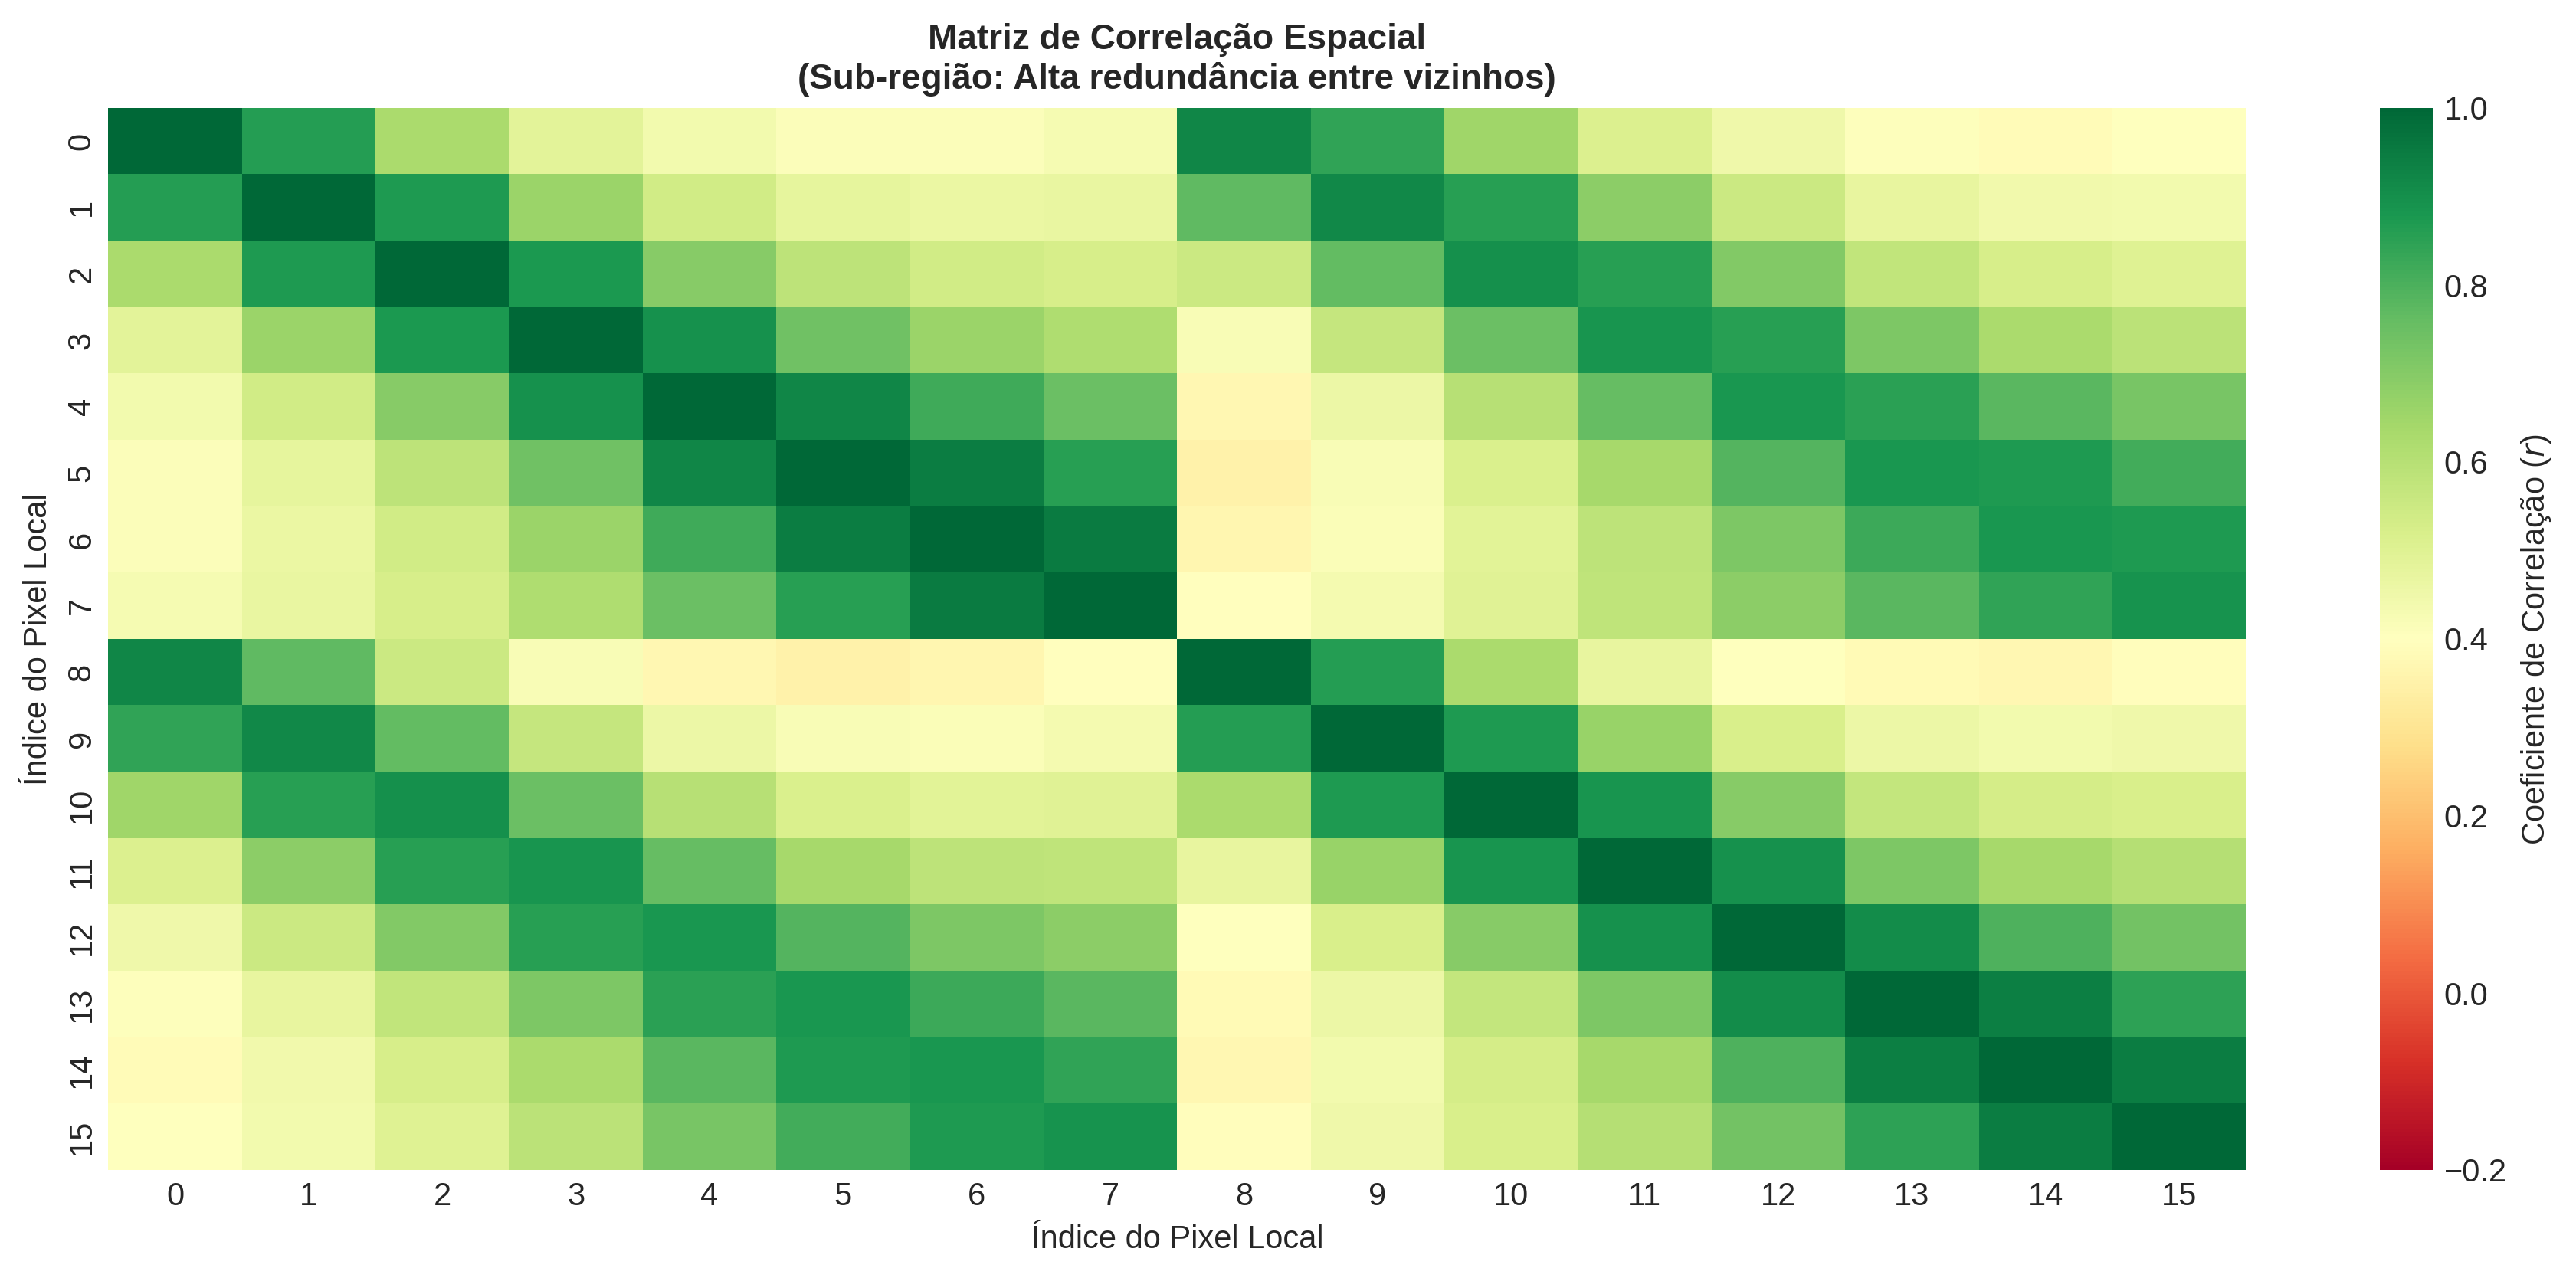

In [ ]:
faces = lfw_dataset.images
target = lfw_dataset.target
names = lfw_dataset.target_names

fig = plt.figure(figsize=(15, 6), dpi=300)
gs = fig.add_gridspec(1, 1, width_ratios=[1], height_ratios=[1], wspace=0.35, hspace=0.4)

# Matriz de Correlação entre Pixels Vizinhos (Bloco 8x8 da região dos olhos)
# Seleção de uma janela central de 8x8 pixels para inspeção local
bloco_pixels = faces[:, 20:28, 20:28].reshape(len(faces), 64)
matriz_corr = np.corrcoef(bloco_pixels, rowvar=False)

ax_corr = fig.add_subplot(gs[:, 0])
sns.heatmap(matriz_corr[:16, :16], cmap='RdYlGn', vmin=-0.2, vmax=1.0, cbar_kws={'label': 'Coeficiente de Correlação ($r$)'}, ax=ax_corr)
ax_corr.set_title("Matriz de Correlação Espacial\n(Sub-região: Alta redundância entre vizinhos)", fontsize=11, fontweight='bold')
ax_corr.set_xlabel("Índice do Pixel Local", fontsize=10)
ax_corr.set_ylabel("Índice do Pixel Local", fontsize=10)

plt.show()

Desafios:
- Maldição da Dimensionalidade: 1850 pixels geram um espaço esparso de dados
- Pixels vizinhos entre si possuem forte covariância e repetem informação
- Ruído: Fundo, roupas e iluminação dominam a variação de pixels, roubando a atenção da geometria do rosto

## Representação gráfica do Problema

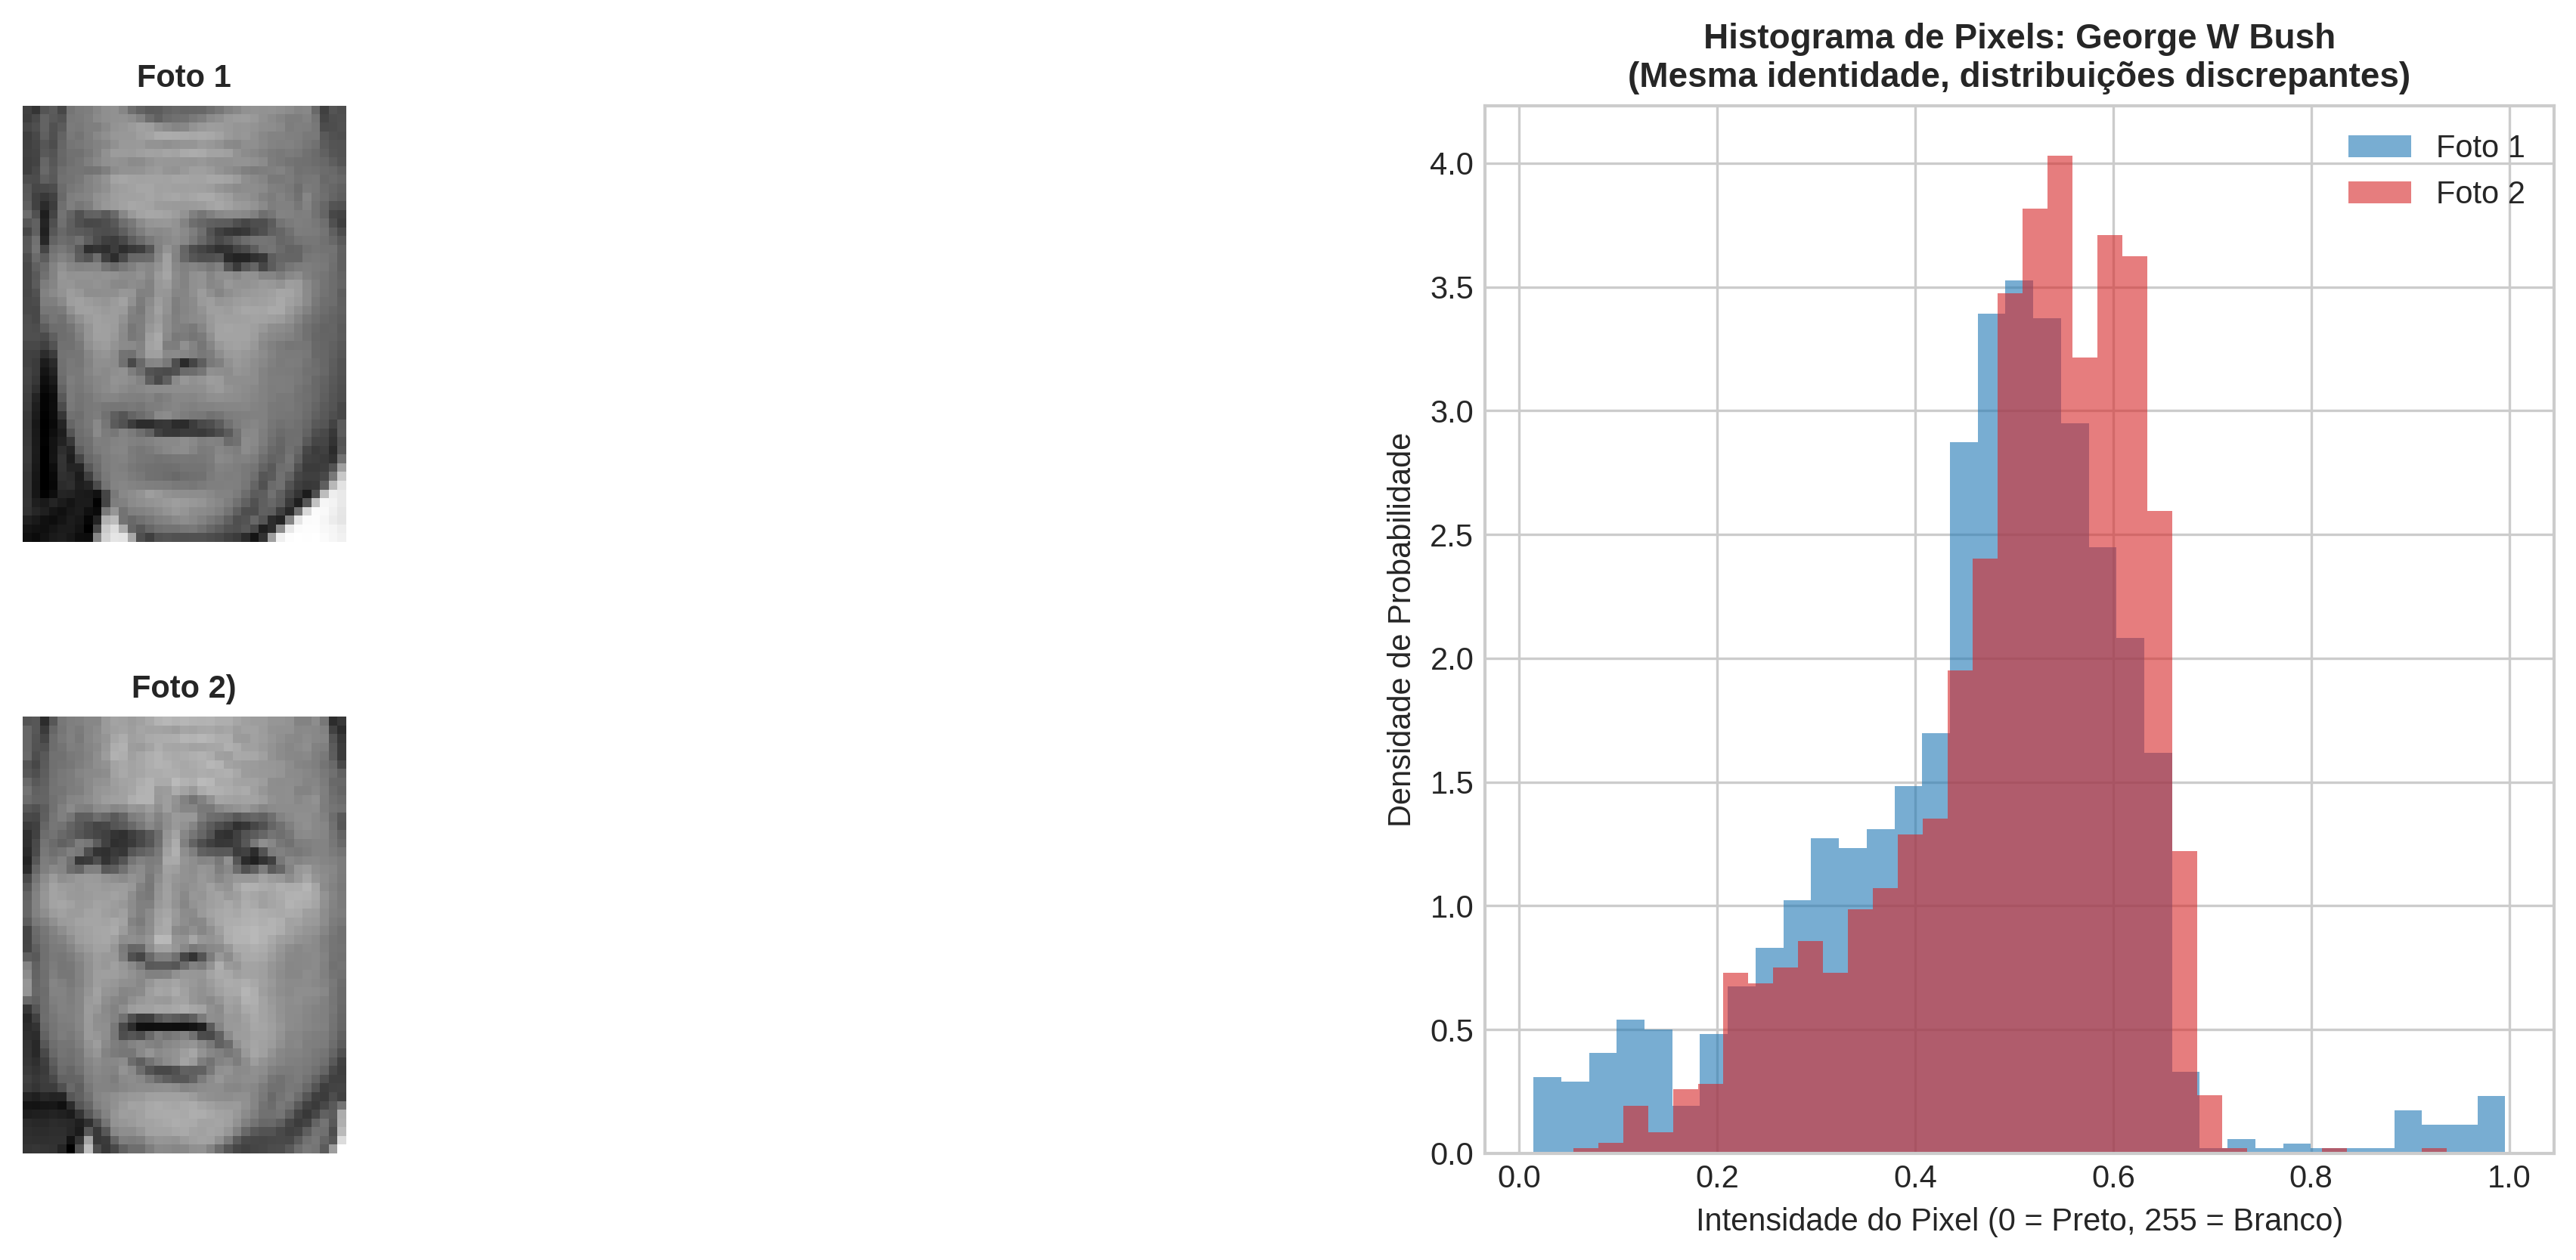

In [ ]:
faces = lfw_dataset.images
target = lfw_dataset.target
names = lfw_dataset.target_names

# Seleciona as duas primeiras fotos da pessoa com mais imagens no banco
id_mais_frequente = np.bincount(target).argmax()
indices = np.where(target == id_mais_frequente)[0]
foto_1, foto_2 = faces[indices[0]], faces[indices[1]]
nome_individuo = names[id_mais_frequente]

# 2. Criação do Painel do Slide 3
fig = plt.figure(figsize=(15, 6), dpi=300)
gs = fig.add_gridspec(2, 3, width_ratios=[1, 1, 2], height_ratios=[1, 1], wspace=0.35, hspace=0.4)

# Painel A: Foto 1 e Foto 2 da mesma pessoa
ax_foto1 = fig.add_subplot(gs[0, 0])
ax_foto1.imshow(foto_1, cmap='gray')
ax_foto1.set_title("Foto 1", fontsize=10, fontweight='bold')
ax_foto1.axis('off')

ax_foto2 = fig.add_subplot(gs[1, 0])
ax_foto2.imshow(foto_2, cmap='gray')
ax_foto2.set_title("Foto 2)", fontsize=10, fontweight='bold')
ax_foto2.axis('off')

# Painel B: Histograma de Luminosidade
ax_hist = fig.add_subplot(gs[:, 2])
ax_hist.hist(foto_1.ravel(), bins=35, color='#1f77b4', alpha=0.6, label='Foto 1', density=True)
ax_hist.hist(foto_2.ravel(), bins=35, color='#d62728', alpha=0.6, label='Foto 2', density=True)
ax_hist.set_title(f"Histograma de Pixels: {nome_individuo}\n(Mesma identidade, distribuições discrepantes)", fontsize=11, fontweight='bold')
ax_hist.set_xlabel("Intensidade do Pixel (0 = Preto, 255 = Branco)", fontsize=10)
ax_hist.set_ylabel("Densidade de Probabilidade", fontsize=10)
ax_hist.legend(loc='upper right')

plt.show()

- Demonstração da sensibilidade a ruídos (comparação da foto 1 com mais fundo e presença do colarinho branco, e da foto 2, focada no rosto)

## Treinamento do Modelo de Random Forest

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

# Extração de atributos via PCA (Eigenfaces) e redução do espaço de pixels para 100 autovetores principais
n_components = 100
pca = PCA(n_components=n_components, svd_solver='randomized', whiten=True, random_state=42)
pca.fit(X_train)

X_train_pca = pca.transform(X_train)
X_test_pca = pca.transform(X_test)

rf_clf = RandomForestClassifier(n_estimators=250,max_features='sqrt',min_samples_split=4,random_state=42,n_jobs=-1)
rf_clf.fit(X_train_pca, y_train)

RandomForestClassifier(min_samples_split=4, n_estimators=250, n_jobs=-1,
                       random_state=42)

## Representação das Eingenfaces

<>:8: SyntaxWarning: invalid escape sequence '\m'
<>:8: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_1357/1414212365.py:8: SyntaxWarning: invalid escape sequence '\m'
  ax_mean.set_title("Face Média\n($\mathbf{\mu}$ Global)", fontsize=12, fontweight='bold')


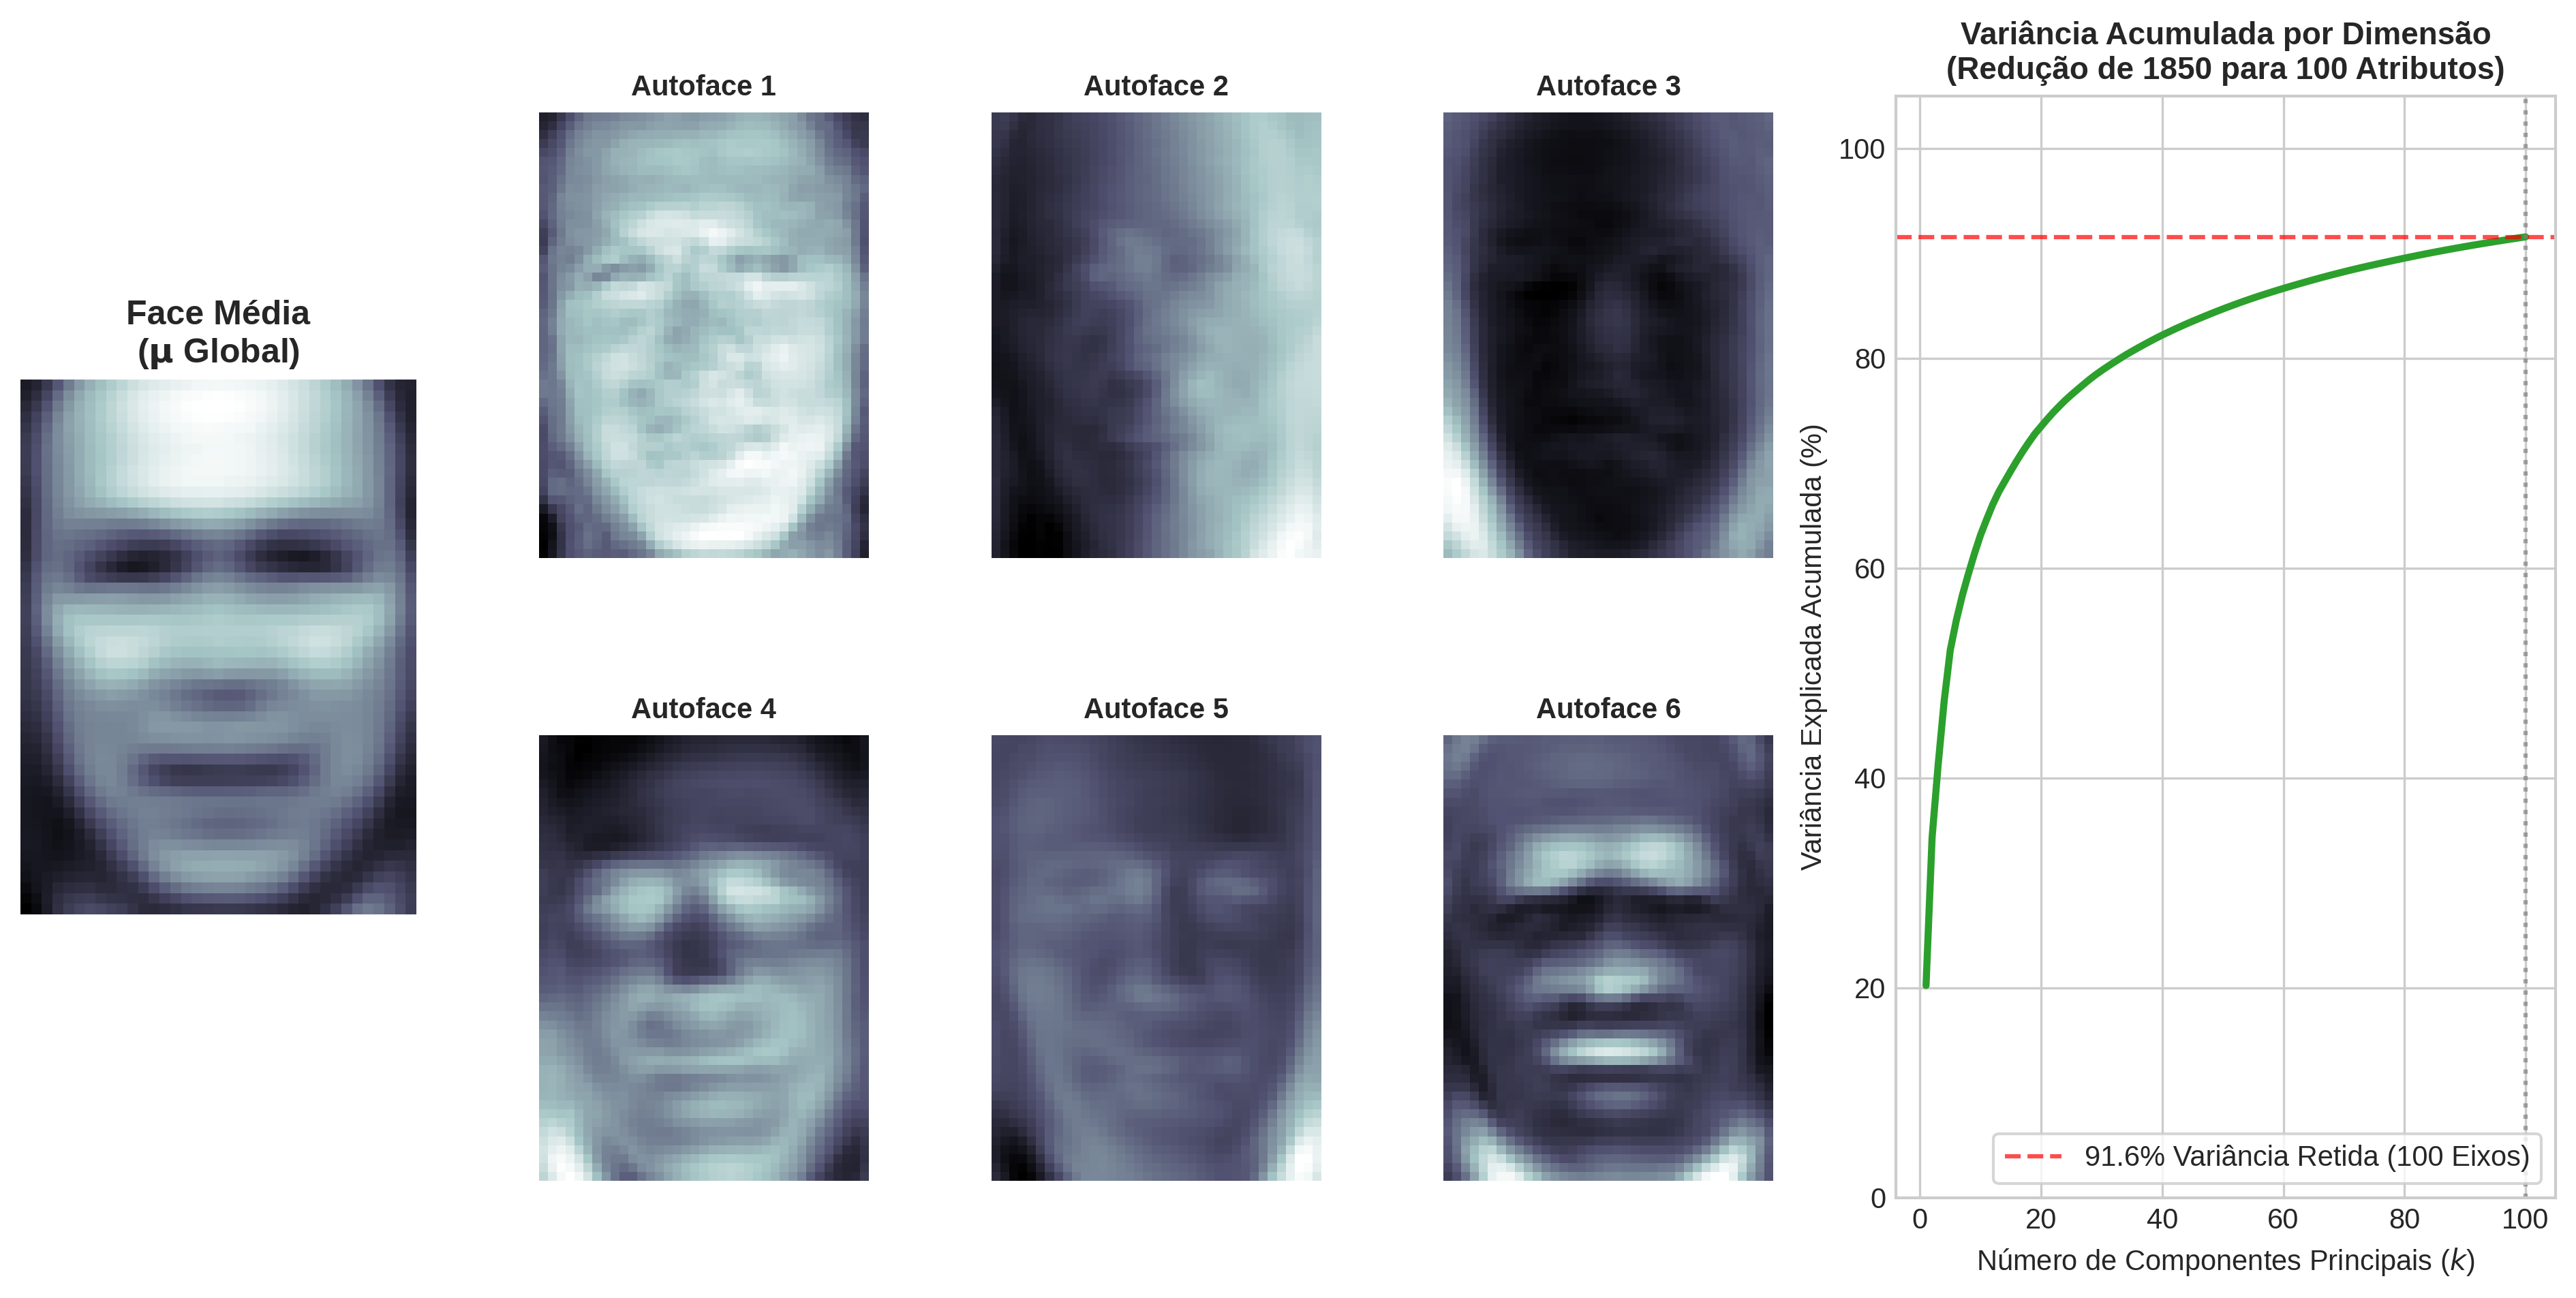

In [ ]:
fig = plt.figure(figsize=(16, 7), dpi=300)
gs = fig.add_gridspec(2, 5, width_ratios=[1.2, 1, 1, 1, 2], hspace=0.3, wspace=0.3)

# Painel A: Rosto Médio
ax_mean = fig.add_subplot(gs[:, 0])
face_media = pca.mean_.reshape((h, w))
ax_mean.imshow(face_media, cmap='bone')
ax_mean.set_title("Face Média\n($\mathbf{\mu}$ Global)", fontsize=12, fontweight='bold')
ax_mean.axis('off')

# Painel B: Primeiras 6 Autofaces (Eigenfaces) organizadas em grade 2x3
titulos_eigen = ["Autoface 1", "Autoface 2", "Autoface 3","Autoface 4", "Autoface 5", "Autoface 6"]

for idx in range(6):
    r = idx // 3
    c = 1 + (idx % 3)
    ax_eig = fig.add_subplot(gs[r, c])
    eigenface = pca.components_[idx].reshape((h, w))
    ax_eig.imshow(eigenface, cmap='bone')
    ax_eig.set_title(titulos_eigen[idx], fontsize=10, fontweight='bold')
    ax_eig.axis('off')

# Painel C: Curva de Variância Explicada Acumulada
ax_var = fig.add_subplot(gs[:, 4])
variancia_acumulada = np.cumsum(pca.explained_variance_ratio_) * 100

ax_var.plot(range(1, n_components + 1), variancia_acumulada, color='#2ca02c', linewidth=2.5)
ax_var.axhline(y=variancia_acumulada[-1], color='red', linestyle='--', alpha=0.7, label=f'{variancia_acumulada[-1]:.1f}% Variância Retida (100 Eixos)')
ax_var.axvline(x=100, color='gray', linestyle=':', alpha=0.7)

ax_var.set_title("Variância Acumulada por Dimensão\n(Redução de 1850 para 100 Atributos)", fontsize=11, fontweight='bold')
ax_var.set_xlabel("Número de Componentes Principais ($k$)", fontsize=10)
ax_var.set_ylabel("Variância Explicada Acumulada (%)", fontsize=10)
ax_var.set_ylim(0, 105)
ax_var.legend(loc='lower right', frameon=True)

plt.show()

- Representação da pura morfologia genérica da base
- As autofaces 1 e 2 destacam as variações de luminosidade, enquanto as de 3 a 6 mapeiam variações estruturais anatômicas
- Redução de 1850 pixels para 100 coeficientes conínuos mantendo 91.6% da variância

## Avaliação de Desempenho do Modelo

### Métricas de Avaliação

In [ ]:
y_pred = rf_clf.predict(X_test_pca)

acc = accuracy_score(y_test, y_pred)
print(f"\nAcurácia Global no Teste: {acc * 100:.2f}%\n")
print("Relatório de Classificação por Indivíduo:")
print(classification_report(y_test, y_pred, target_names=target_names))


Acurácia Global no Teste: 53.12%

Relatório de Classificação por Indivíduo:
                   precision    recall  f1-score   support

     Ariel Sharon       1.00      0.05      0.10        19
     Colin Powell       0.76      0.66      0.71        59
  Donald Rumsfeld       0.00      0.00      0.00        30
    George W Bush       0.47      0.95      0.63       133
Gerhard Schroeder       0.75      0.11      0.19        27
      Hugo Chavez       0.00      0.00      0.00        18
Junichiro Koizumi       1.00      0.20      0.33        15
       Tony Blair       0.86      0.17      0.28        36

         accuracy                           0.53       337
        macro avg       0.61      0.27      0.28       337
     weighted avg       0.57      0.53      0.44       337



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


- Fenômeno Bush: O modelo se tornou uma espécie de "Preditor de Bush", chutando esta classificação em situações de dúvida, graças ao fato desta personalidade compor quase 40% do conjunto de teste
- Comparar o Recall de 95% com a Precisão de 0.47% para Bush
- Penalização das classes minoritárias a fim de minimizar o Gini (destaque para os 0% de Recall para Hugo Chavez, que tem apenas 18 fotos, e Donald Rumsfeld, que tem 30)

### Matriz de Confusão

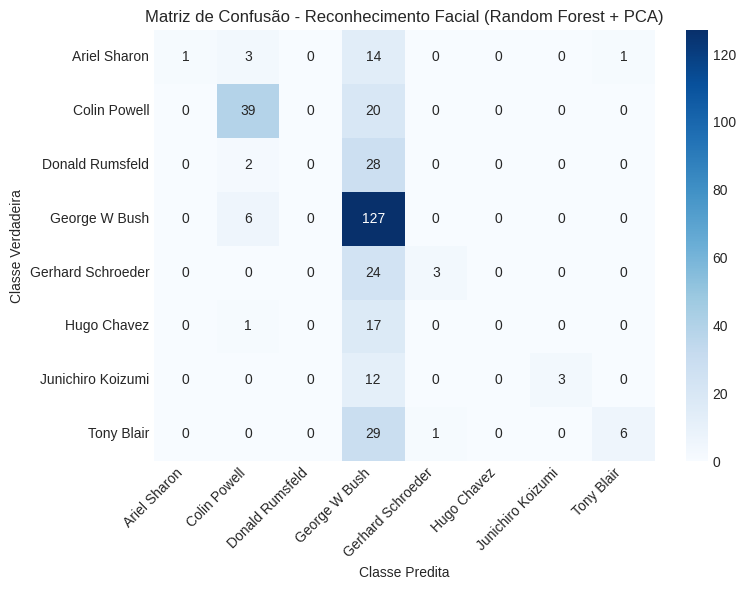

In [ ]:
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names)
plt.title("Matriz de Confusão - Reconhecimento Facial (Random Forest + PCA)")
plt.xlabel("Classe Predita")
plt.ylabel("Classe Verdadeira")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Conclusões
- Pela natureza das projeções PCA geradas (distribuições de probabilidade angulares/esféricas), talvez fosse melhor a adoção de outros modelos como SVM
- O PCA assume faces estáticas e alinhadas, tendo maior dificuldade com fotos "in the wild"
- Soluções: Balanceamento de Custo (Penalização maior de erros nas classes minoritárias) ou adoção de outro dataset (como o Olivetti Faces).

## Comparação com SVM Classifier

In [ ]:
from sklearn import svm

clf = svm.SVC(kernel='linear')
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

acc = accuracy_score(y_test, y_pred)
print(f"\nAcurácia Global no Teste: {acc * 100:.2f}%\n")
print("Relatório de Classificação por Indivíduo:")
print(classification_report(y_test, y_pred, target_names=target_names))


Acurácia Global no Teste: 81.01%

Relatório de Classificação por Indivíduo:
                   precision    recall  f1-score   support

     Ariel Sharon       0.60      0.63      0.62        19
     Colin Powell       0.82      0.86      0.84        59
  Donald Rumsfeld       0.82      0.60      0.69        30
    George W Bush       0.84      0.89      0.87       133
Gerhard Schroeder       0.82      0.85      0.84        27
      Hugo Chavez       1.00      0.61      0.76        18
Junichiro Koizumi       0.73      0.73      0.73        15
       Tony Blair       0.76      0.78      0.77        36

         accuracy                           0.81       337
        macro avg       0.80      0.75      0.76       337
     weighted avg       0.81      0.81      0.81       337



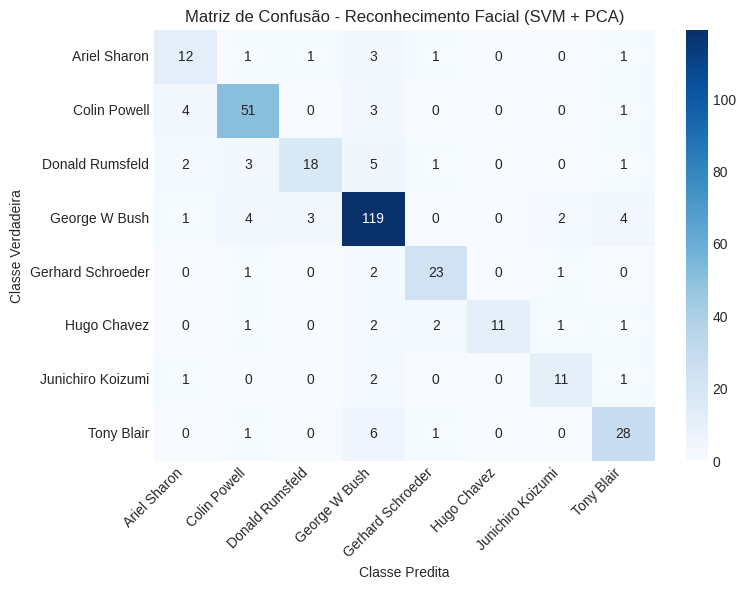

In [ ]:
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names)
plt.title("Matriz de Confusão - Reconhecimento Facial (SVM + PCA)")
plt.xlabel("Classe Predita")
plt.ylabel("Classe Verdadeira")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()